# CSET485 – AI and Society | Assignment 1 — Code Components
**Roll number:** 1548 · **Dataset:** Adult Census Income · **Random seed:** 548 · **Split:** 70/30

This notebook covers preprocessing, Part 1, and Part 2.1–2.4. As requested, it excludes the eight written answers in Part 3 and the reflection in Part 4. Run all cells from top to bottom and use only your computed outputs in the report.

## 0. Setup

In [1]:
!pip -q install statsmodels
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, accuracy_score

ROLL_NUMBER = 1548
RANDOM_SEED = 548  # Last three digits of roll number 1548
np.random.seed(RANDOM_SEED)
print("Roll number:", ROLL_NUMBER, "| Random seed:", RANDOM_SEED)

Roll number: 1548 | Random seed: 548


## 1. Load the assigned Adult Census Income dataset

In [2]:
# Last digit of roll number is 8, so the assignment specifies Adult Census Income.
columns = ["age","workclass","fnlwgt","education","education_num","marital_status",
           "occupation","relationship","race","sex","capital_gain","capital_loss",
           "hours_per_week","native_country","income"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
df = pd.read_csv(url, header=None, names=columns, na_values="?", skipinitialspace=True)
for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()
df["income"] = df["income"].replace({">50K.":">50K", "<=50K.":"<=50K"})
df["income_binary"] = (df["income"] == ">50K").astype(int)
print("Dataset shape:", df.shape)
display(df.head())
display(df["income"].value_counts().to_frame("count"))

Dataset shape: (32561, 16)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


,count
income,
<=50K,24720
>50K,7841


## 2. Preprocessing and train/test split
Missing numeric values will be median-imputed; categorical values use the most frequent category. Categorical variables are one-hot encoded and numeric variables standardized. Numeric percentiles are inspected for outliers; extreme values are not automatically deleted because they may be valid observations.

In [3]:
print("Missing values before imputation:")
display(df.isna().sum().loc[lambda x: x.gt(0)].to_frame("missing_count"))
num_inspect = ["age","fnlwgt","education_num","capital_gain","capital_loss","hours_per_week"]
display(df[num_inspect].describe(percentiles=[.01,.25,.5,.75,.99]).T)

X = df.drop(columns=["income","income_binary"])
y = df["income_binary"].astype(int)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer",SimpleImputer(strategy="median")),
                      ("scaler",StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                      ("onehot",OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.30, random_state=RANDOM_SEED, stratify=y
)
print(f"Total={len(X)} | Train={len(X_train)} ({len(X_train)/len(X):.1%}) | Test={len(X_test)} ({len(X_test)/len(X):.1%})")

Missing values before imputation:


,missing_count
workclass,1836
occupation,1843
native_country,583


,count,mean,std,min,1%,25%,50%,75%,99%,max
age,32561.0,38.581647,13.640433,17.0,17.0,28.0,37.0,48.0,74.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,27185.8,117827.0,178356.0,237051.0,510072.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,3.0,9.0,10.0,12.0,16.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,0.0,15024.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,0.0,1980.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,8.0,40.0,40.0,45.0,80.0,99.0


Total=32561 | Train=22792 (70.0%) | Test=9769 (30.0%)


## Part 1 — Linear Regression vs Logistic Regression
The Linear Regression predictions use their test-set median as cutoff; Logistic Regression probabilities use 0.5. The confusion matrix compares agreement between these two classification approaches.

In [4]:
linear_model = Pipeline([("prep",preprocessor),("model",LinearRegression())])
logistic_model = Pipeline([("prep",preprocessor),
                           ("model",LogisticRegression(max_iter=2000, random_state=RANDOM_SEED))])
linear_model.fit(X_train,y_train)
logistic_model.fit(X_train,y_train)
linear_pred = linear_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:,1]
linear_threshold = float(np.median(linear_pred))
linear_class = (linear_pred >= linear_threshold).astype(int)
logistic_class = (logistic_prob >= .5).astype(int)

cm = confusion_matrix(linear_class,logistic_class,labels=[0,1])
cm_table = pd.DataFrame(cm,index=["Linear: low (0)","Linear: high (1)"],
                        columns=["Logistic: low (0)","Logistic: high (1)"])
mismatch = linear_class != logistic_class
print(f"Linear median prediction threshold = {linear_threshold:.6f}")
print("Logistic probability threshold = 0.500000")
display(cm_table)
print(f"Mismatches: {mismatch.sum()} / {len(y_test)} ({100*mismatch.mean():.2f}%)")
print("\nLogistic model vs actual test labels:")
print(classification_report(y_test,logistic_class,zero_division=0))
print("Accuracy:", round(accuracy_score(y_test,logistic_class),4))
print("ROC-AUC:", round(roc_auc_score(y_test,logistic_prob),4))

Linear median prediction threshold = 0.230848
Logistic probability threshold = 0.500000


,Logistic: low (0),Logistic: high (1)
Linear: low (0),4870,14
Linear: high (1),2938,1947


Mismatches: 2952 / 9769 (30.22%)

Logistic model vs actual test labels:
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      7417
           1       0.73      0.61      0.66      2352

    accuracy                           0.85      9769
   macro avg       0.81      0.77      0.79      9769
weighted avg       0.85      0.85      0.85      9769

Accuracy: 0.8521
ROC-AUC: 0.9056


## Part 2.1 — Subgroup coefficient analysis
Fit logistic models on the full dataset, Female subgroup, and Male subgroup. The `education_num` coefficient is reported with a 95% confidence interval and p-value. Only claim a sign reversal if the output actually shows one.

In [5]:
# Use interpretable variables and impute missing numeric values for statsmodels.
sub = df[["income_binary","education_num","age","hours_per_week","capital_gain","capital_loss","sex"]].copy()
for c in ["education_num","age","hours_per_week","capital_gain","capital_loss"]:
    sub[c] = sub[c].fillna(sub[c].median())
sub["sex"] = sub["sex"].fillna(sub["sex"].mode().iloc[0]).astype(str)

def fit_logit(formula, data):
    return smf.glm(formula=formula,data=data,family=sm.families.Binomial()).fit(maxiter=200)

m_full = fit_logit("income_binary ~ education_num + age + hours_per_week + capital_gain + capital_loss + C(sex)",sub)
female = sub[sub.sex=="Female"]
male = sub[sub.sex=="Male"]
m_female = fit_logit("income_binary ~ education_num + age + hours_per_week + capital_gain + capital_loss",female)
m_male = fit_logit("income_binary ~ education_num + age + hours_per_week + capital_gain + capital_loss",male)

def coef_row(model, term, group):
    ci = model.conf_int().loc[term]
    return {"group":group,"predictor":term,"coefficient":model.params[term],
            "CI 95% lower":ci.iloc[0],"CI 95% upper":ci.iloc[1],"p-value":model.pvalues[term]}
subgroup_table = pd.DataFrame([
    coef_row(m_full,"education_num","Full dataset"),
    coef_row(m_female,"education_num","Female subgroup"),
    coef_row(m_male,"education_num","Male subgroup")
])
subgroup_display = subgroup_table.copy()
numeric_cols = ["coefficient", "CI 95% lower", "CI 95% upper"]
subgroup_display[numeric_cols] = subgroup_display[numeric_cols].round(6)

def format_pvalue(p):
    return "p < 0.001" if p < 0.001 else f"{p:.4f}"

subgroup_display["p-value"] = subgroup_table["p-value"].apply(format_pvalue)
display(subgroup_display)
if np.sign(m_female.params["education_num"]) != np.sign(m_male.params["education_num"]):
    print("The education_num coefficient changes sign between Female and Male subgroup models.")
else:
    print("No sign reversal between Female and Male subgroup models; compare effect size, confidence intervals and p-values.")

,group,predictor,coefficient,CI 95% lower,CI 95% upper,p-value
0,Full dataset,education_num,0.333697,0.320082,0.347311,p < 0.001
1,Female subgroup,education_num,0.345327,0.313009,0.377645,p < 0.001
2,Male subgroup,education_num,0.334063,0.318931,0.349195,p < 0.001


No sign reversal between Female and Male subgroup models; compare effect size, confidence intervals and p-values.


## Part 2.2 — Omitted-variable bias
The full model uses the available predictors while avoiding duplicate representations of education: `education_num` is retained and the categorical `education` column is omitted because it encodes the same underlying attainment. This avoids a rank-deficient design matrix. The reduced model then omits `sex`. Compare at least four predictor coefficients and their percentage changes. Percentage changes can be unstable if a full-model coefficient is close to zero.

In [6]:
# Prepare the Adult dataset for full/reduced statsmodels logistic models.
ovb = df.drop(columns=["income", "education"]).copy()  # retain education_num to avoid duplicate coding
for c in ovb.select_dtypes(include="number").columns:
    if c != "income_binary":
        ovb[c] = ovb[c].fillna(ovb[c].median())
for c in ovb.select_dtypes(exclude="number").columns:
    ovb[c] = ovb[c].fillna(ovb[c].mode().iloc[0]).astype(str)

predictors = ["age","workclass","fnlwgt","education_num","marital_status",
              "occupation","relationship","race","sex","capital_gain","capital_loss",
              "hours_per_week","native_country"]

def formula_for(cols):
    terms = [c if pd.api.types.is_numeric_dtype(ovb[c]) else f"C({c})" for c in cols]
    return "income_binary ~ " + " + ".join(terms)

full_ovb = fit_logit(formula_for(predictors), ovb)
reduced_predictors = [c for c in predictors if c != "sex"]
reduced_ovb = fit_logit(formula_for(reduced_predictors), ovb)

compare_predictors = ["age","education_num","hours_per_week","capital_gain","capital_loss"]
rows = []
for p in compare_predictors:
    before, after = float(full_ovb.params[p]), float(reduced_ovb.params[p])
    shift = after - before
    pct = np.nan if abs(before) < 1e-8 else shift / before * 100
    rows.append({"predictor":p,"full coefficient":before,"reduced coefficient":after,
                 "coefficient shift":shift,"signed change (%)":pct,
                 "absolute change (%)":abs(pct) if pd.notna(pct) else np.nan})
ovb_table = pd.DataFrame(rows)
display(ovb_table.round(6))
valid = ovb_table.dropna(subset=["absolute change (%)"])
if len(valid):
    largest = valid.loc[valid["absolute change (%)"].idxmax()]
    print(f"Largest absolute percentage change: {largest['predictor']} ({largest['absolute change (%)']:.2f}%)")
print("Omitted variable in reduced model: sex")


,predictor,full coefficient,reduced coefficient,coefficient shift,signed change (%),absolute change (%)
0,age,0.023463,0.023506,0.000043,0.182636,0.182636
1,education_num,0.300102,0.301304,0.001202,0.400578,0.400578
2,hours_per_week,0.032101,0.032806,0.000704,2.194123,2.194123
3,capital_gain,0.000314,0.000314,0.000000,0.122588,0.122588
4,capital_loss,0.000650,0.000653,0.000003,0.407343,0.407343


Largest absolute percentage change: hours_per_week (2.19%)
Omitted variable in reduced model: sex


## Part 2.3 — Adversarial subset
Find high-confidence false positives (P ≥ 0.75 but actual 0) and false negatives (P ≤ 0.25 but actual 1). Report the total and percentage of test cases, select up to 50 using seed 548, and compare demographic summaries with the full test set.

In [7]:
adv = X_test.copy()
adv["actual"] = np.asarray(y_test)
adv["predicted_probability"] = logistic_prob
adv["predicted_label"] = logistic_class
fp = (adv.predicted_probability >= .75) & (adv.actual == 0)
fn = (adv.predicted_probability <= .25) & (adv.actual == 1)
all_errors = adv[fp | fn].copy()
print("High-confidence incorrect predictions:",len(all_errors))
print(f"Percentage of test set: {100*len(all_errors)/len(X_test):.3f}%")
adversarial_sample = all_errors.sample(50,random_state=RANDOM_SEED) if len(all_errors)>50 else all_errors.copy()
print("Rows selected:",len(adversarial_sample))
display(adversarial_sample.head(10))

def demo_summary(frame,name):
    return {"dataset":name,"rows":len(frame),"mean age":frame["age"].mean(),
            "median age":frame["age"].median(),
            "female (%)":100*(frame["sex"]=="Female").mean()}
demo_table = pd.DataFrame([
    demo_summary(X_test,"Full test set"),
    demo_summary(adversarial_sample,"Adversarial subset")
])
display(demo_table.round(3))
if len(adversarial_sample):
    display((adversarial_sample["sex"].value_counts(normalize=True)*100).round(2).to_frame("gender percent"))
    display(adversarial_sample["age"].describe().to_frame("age"))
adversarial_sample.to_csv("adversarial_subset.csv",index=True)
print("Saved adversarial_subset.csv")

High-confidence incorrect predictions: 453
Percentage of test set: 4.637%
Rows selected: 50


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,actual,predicted_probability,predicted_label
13516,45,Local-gov,364563,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,1,0.243751,0
28123,37,Self-emp-not-inc,82540,9th,5,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,70,United-States,1,0.132481,0
2282,31,Private,219509,HS-grad,9,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,Mexico,1,0.043012,0
25137,48,Private,149210,Bachelors,13,Divorced,Sales,Not-in-family,Black,Male,0,0,40,United-States,1,0.186642,0
415,35,Private,92440,12th,8,Divorced,Craft-repair,Not-in-family,White,Male,0,0,50,United-States,1,0.041022,0
12109,46,Private,120131,Bachelors,13,Married-civ-spouse,Other-service,Husband,White,Male,0,0,30,United-States,1,0.238031,0
14640,29,State-gov,147256,Assoc-acdm,12,Never-married,Prof-specialty,Not-in-family,Black,Male,0,0,40,United-States,1,0.036135,0
17366,38,Private,48779,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,1,0.242933,0
23868,77,Private,83601,Prof-school,15,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,0,0.909401,1
9561,56,Private,174533,Bachelors,13,Never-married,Exec-managerial,Not-in-family,White,Female,0,0,45,United-States,1,0.143918,0


,dataset,rows,mean age,median age,female (%)
0,Full test set,9769,38.643,37.0,33.494
1,Adversarial subset,50,42.100,40.0,24.000


,gender percent
sex,
Male,76.0
Female,24.0


,age
count,50.000000
mean,42.100000
std,12.012324
min,19.000000
25%,34.000000
50%,40.000000
75%,49.500000
max,77.000000


Saved adversarial_subset.csv


In [8]:
# Explore possible common characteristics; use the output to choose a pattern supported by the data.
if len(adversarial_sample):
    for col in ["workclass","education","marital_status","occupation","relationship","race","sex"]:
        print(f"Top values in {col} (%):")
        display((adversarial_sample[col].value_counts(normalize=True).head(8)*100).round(2).to_frame("percent"))
    numeric_cols = ["age","education_num","hours_per_week","capital_gain","capital_loss","predicted_probability"]
    display(adversarial_sample[numeric_cols].describe().round(3))
    comparison = []
    for col in ["age","education_num","hours_per_week","capital_gain","capital_loss"]:
        comparison.append({"feature":col,"test mean":X_test[col].mean(),
                           "subset mean":adversarial_sample[col].mean(),
                           "difference":adversarial_sample[col].mean()-X_test[col].mean()})
    display(pd.DataFrame(comparison).round(3))
else:
    print("No cases met the confidence/error criteria. Report this result; do not fabricate rows.")

Top values in workclass (%):


,percent
workclass,
Private,74.0
Local-gov,10.0
Self-emp-not-inc,6.0
State-gov,6.0
Self-emp-inc,2.0
Federal-gov,2.0


Top values in education (%):


,percent
education,
HS-grad,32.0
Bachelors,24.0
Some-college,16.0
Assoc-voc,8.0
Masters,6.0
Prof-school,6.0
9th,2.0
12th,2.0


Top values in marital_status (%):


...

,percent
race,
White,88.0
Black,10.0
Asian-Pac-Islander,2.0


Top values in sex (%):


,percent
sex,
Male,76.0
Female,24.0


,age,education_num,hours_per_week,capital_gain,capital_loss,predicted_probability
count,50.000,50.000,50.000,50.000,50.000,50.000
mean,42.100,10.840,40.920,846.920,106.280,0.262
std,12.012,2.324,8.946,4868.726,425.609,0.279
min,19.000,5.000,10.000,0.000,0.000,0.007
25%,34.000,9.000,40.000,0.000,0.000,0.077
50%,40.000,10.000,40.000,0.000,0.000,0.168
75%,49.500,13.000,44.500,0.000,0.000,0.240
max,77.000,15.000,70.000,34095.000,1902.000,0.964


,feature,test mean,subset mean,difference
0,age,38.643,42.10,3.457
1,education_num,10.082,10.84,0.758
2,hours_per_week,40.433,40.92,0.487
3,capital_gain,1014.477,846.92,-167.557
4,capital_loss,82.459,106.28,23.821


## Part 2.4 — Fairness metrics across thresholds
Sensitive attribute: `sex`; Group A = Female, Group B = Male. DP = selection-rate ratio, EO = minimum of TPR ratio and FPR ratio, PP = precision ratio. Ideal ratio is 1.0. Undefined ratios are shown as NaN when a denominator is zero.

In [9]:
fair = X_test[["sex"]].copy()
fair["actual"] = np.asarray(y_test)
fair["probability"] = logistic_prob

def ratio(a,b):
    return np.nan if pd.isna(a) or pd.isna(b) or b==0 else a/b

def group_rates(g,t):
    actual = g.actual.to_numpy(dtype=int)
    pred = (g.probability.to_numpy() >= t).astype(int)
    pos, neg, pred_pos = actual==1, actual==0, pred==1
    return {
        "selection":float(pred_pos.mean()) if len(g) else np.nan,
        "TPR":float((pred[pos]==1).mean()) if pos.sum() else np.nan,
        "FPR":float((pred[neg]==1).mean()) if neg.sum() else np.nan,
        "precision":float((actual[pred_pos]==1).mean()) if pred_pos.sum() else np.nan
    }

thresholds = np.round(np.arange(.05,.951,.10),2)
fair_rows = []
for t in thresholds:
    a = group_rates(fair[fair.sex=="Female"],t)
    b = group_rates(fair[fair.sex=="Male"],t)
    tpr_ratio, fpr_ratio = ratio(a["TPR"],b["TPR"]), ratio(a["FPR"],b["FPR"])
    eo = min(tpr_ratio,fpr_ratio) if pd.notna(tpr_ratio) and pd.notna(fpr_ratio) else np.nan
    fair_rows.append({
        "threshold":t,"DP ratio":ratio(a["selection"],b["selection"]),
        "EO ratio":eo,"PP ratio":ratio(a["precision"],b["precision"]),
        "Female selection rate":a["selection"],"Male selection rate":b["selection"],
        "Female TPR":a["TPR"],"Male TPR":b["TPR"],
        "Female FPR":a["FPR"],"Male FPR":b["FPR"],
        "Female precision":a["precision"],"Male precision":b["precision"]
    })
fairness_table = pd.DataFrame(fair_rows)
display(fairness_table.round(4))

,threshold,DP ratio,EO ratio,PP ratio,Female selection rate,Male selection rate,Female TPR,Male TPR,Female FPR,Male FPR,Female precision,Male precision
0,0.05,0.4385,0.3955,0.7758,0.3240,0.7388,0.9284,0.9889,0.2485,0.6284,0.3179,0.4098
1,0.15,0.2990,0.2279,1.0244,0.1770,0.5918,0.7989,0.9452,0.0993,0.4359,0.5009,0.4889
2,0.25,0.2757,0.1927,1.0808,0.1308,0.4744,0.7190,0.8743,0.0574,0.2979,0.6098,0.5642
3,0.35,0.2955,0.2308,0.9997,0.1097,0.3712,0.6309,0.7738,0.0447,0.1937,0.6379,0.6381
4,0.45,0.2875,0.2118,1.0240,0.0853,0.2966,0.5510,0.6782,0.0272,0.1282,0.7168,0.7001
5,0.55,0.2915,0.2251,1.0033,0.0669,0.2296,0.4601,0.5701,0.0179,0.0794,0.7626,0.7601
6,0.65,0.2920,0.2214,1.0059,0.0492,0.1685,0.3691,0.4555,0.0093,0.0419,0.8323,0.8274
7,0.75,0.2984,0.2494,0.9907,0.0345,0.1157,0.2727,0.3343,0.0048,0.0193,0.8761,0.8843
8,0.85,0.3126,0.3499,0.9693,0.0226,0.0723,0.1846,0.2207,0.0024,0.0069,0.9054,0.9340
9,0.95,0.2568,0.6194,0.8742,0.0092,0.0357,0.0716,0.1156,0.0014,0.0004,0.8667,0.9914


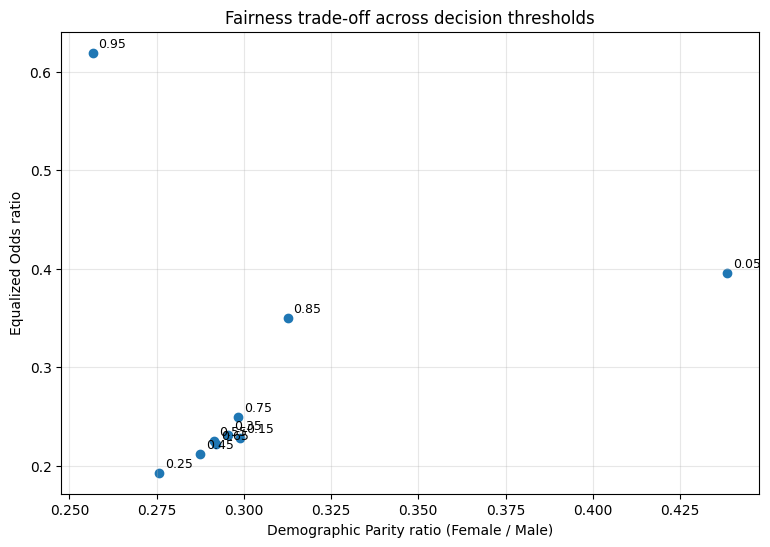

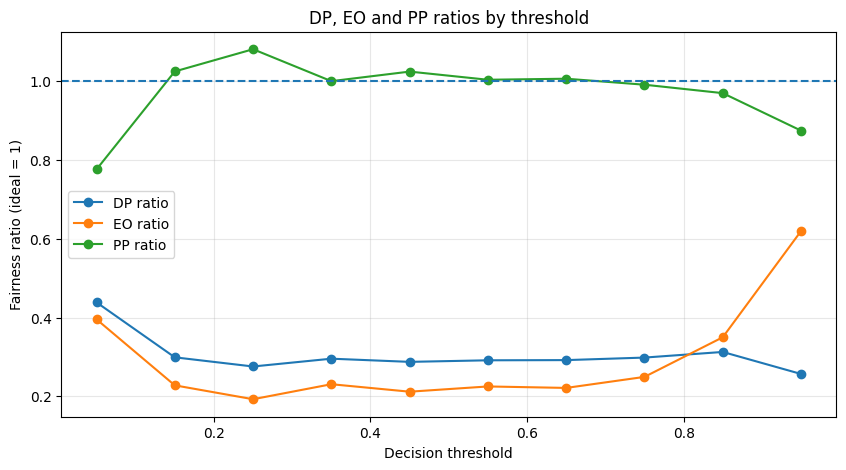

In [10]:
# Required trade-off chart: DP on X-axis, EO on Y-axis; label every point with its threshold.
plot_df = fairness_table.dropna(subset=["DP ratio","EO ratio"])
plt.figure(figsize=(9,6))
plt.scatter(plot_df["DP ratio"],plot_df["EO ratio"])
for _,r in plot_df.iterrows():
    plt.annotate(f'{r["threshold"]:.2f}',(r["DP ratio"],r["EO ratio"]),
                 xytext=(4,4),textcoords="offset points",fontsize=9)
plt.xlabel("Demographic Parity ratio (Female / Male)")
plt.ylabel("Equalized Odds ratio")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(True,alpha=.3); plt.show()

fairness_table.plot(x="threshold",y=["DP ratio","EO ratio","PP ratio"],
                    marker="o",figsize=(10,5))
plt.axhline(1.0,linestyle="--")
plt.xlabel("Decision threshold"); plt.ylabel("Fairness ratio (ideal = 1)")
plt.title("DP, EO and PP ratios by threshold")
plt.grid(True,alpha=.3); plt.show()

In [11]:
# Compare thresholds 0.75 and 0.95 and quantify how each fairness ratio moves
# relative to its ideal value of 1.0.
threshold_start, threshold_end = 0.75, 0.95
r0 = fairness_table.loc[np.isclose(fairness_table["threshold"], threshold_start)].iloc[0]
r1 = fairness_table.loc[np.isclose(fairness_table["threshold"], threshold_end)].iloc[0]

print(f"Comparison: threshold {threshold_start:.2f} vs {threshold_end:.2f}\\n")
for metric in ["DP ratio", "EO ratio", "PP ratio"]:
    value0, value1 = float(r0[metric]), float(r1[metric])
    gap0, gap1 = abs(1 - value0), abs(1 - value1)
    gap_change = ((gap1 - gap0) / gap0 * 100) if gap0 > 0 else np.nan
    print(f"{metric}: {value0:.4f} -> {value1:.4f}")
    print(f"  Change in distance from ideal: {gap_change:+.2f}%")
    if gap_change < 0:
        print("  Interpretation: moved closer to the ideal ratio.")
    elif gap_change > 0:
        print("  Interpretation: moved farther from the ideal ratio.")
    else:
        print("  Interpretation: no change in distance from ideal.")

print("\\nSelection rates:")
print(f"Female: {r0['Female selection rate']:.2%} -> {r1['Female selection rate']:.2%}")
print(f"Male:   {r0['Male selection rate']:.2%} -> {r1['Male selection rate']:.2%}")

print("\\nInterpretation:")
print("Threshold 0.95 improves EO relative to 0.75, but DP and PP move farther")
print("from their ideal values. Selection rates also fall sharply for both groups.")
print("Neither threshold is fair on all metrics; choose based on the policy goal")
print("and the consequences of false positives and false negatives.")

# Identify a balanced candidate by mean absolute distance from 1.0 across all three ratios.
metric_cols = ["DP ratio", "EO ratio", "PP ratio"]
balanced = fairness_table.dropna(subset=metric_cols).copy()
if len(balanced):
    balanced["mean_distance_from_ideal"] = (balanced[metric_cols].sub(1).abs()).mean(axis=1)
    best = balanced.loc[balanced["mean_distance_from_ideal"].idxmin()]
    print(f"\\nBalanced candidate (not a universal fairness optimum): threshold={best['threshold']:.2f}, "
          f"DP={best['DP ratio']:.4f}, EO={best['EO ratio']:.4f}, PP={best['PP ratio']:.4f}, "
          f"mean distance from 1.0={best['mean_distance_from_ideal']:.4f}")


Comparison: threshold 0.75 vs 0.95\n
DP ratio: 0.2984 -> 0.2568
  Change in distance from ideal: +5.93%
  Interpretation: moved farther from the ideal ratio.
EO ratio: 0.2494 -> 0.6194
  Change in distance from ideal: -49.30%
  Interpretation: moved closer to the ideal ratio.
PP ratio: 0.9907 -> 0.8742
  Change in distance from ideal: +1256.24%
  Interpretation: moved farther from the ideal ratio.
\nSelection rates:
Female: 3.45% -> 0.92%
Male:   11.57% -> 3.57%
\nInterpretation:
Threshold 0.95 improves EO relative to 0.75, but DP and PP move farther
from their ideal values. Selection rates also fall sharply for both groups.
Neither threshold is fair on all metrics; choose based on the policy goal
and the consequences of false positives and false negatives.
\nBalanced candidate (not a universal fairness optimum): threshold=0.95, DP=0.2568, EO=0.6194, PP=0.8742, mean distance from 1.0=0.4165


## Export computed tables
This cell saves key outputs as CSV files in the Colab runtime. Download them from the Files panel if needed for your report.

In [12]:
cm_table.to_csv("part1_model_agreement_confusion_matrix.csv")
subgroup_table.to_csv("part2_1_subgroup_coefficients.csv",index=False)
ovb_table.to_csv("part2_2_omitted_variable_bias.csv",index=False)
demo_table.to_csv("part2_3_adversarial_demographics.csv",index=False)
fairness_table.to_csv("part2_4_fairness_metrics.csv",index=False)
print("Saved: part1_model_agreement_confusion_matrix.csv")
print("Saved: part2_1_subgroup_coefficients.csv")
print("Saved: part2_2_omitted_variable_bias.csv")
print("Saved: part2_3_adversarial_demographics.csv")
print("Saved: part2_4_fairness_metrics.csv")
print("Saved: adversarial_subset.csv")

Saved: part1_model_agreement_confusion_matrix.csv
Saved: part2_1_subgroup_coefficients.csv
Saved: part2_2_omitted_variable_bias.csv
Saved: part2_3_adversarial_demographics.csv
Saved: part2_4_fairness_metrics.csv
Saved: adversarial_subset.csv
